In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 2.5

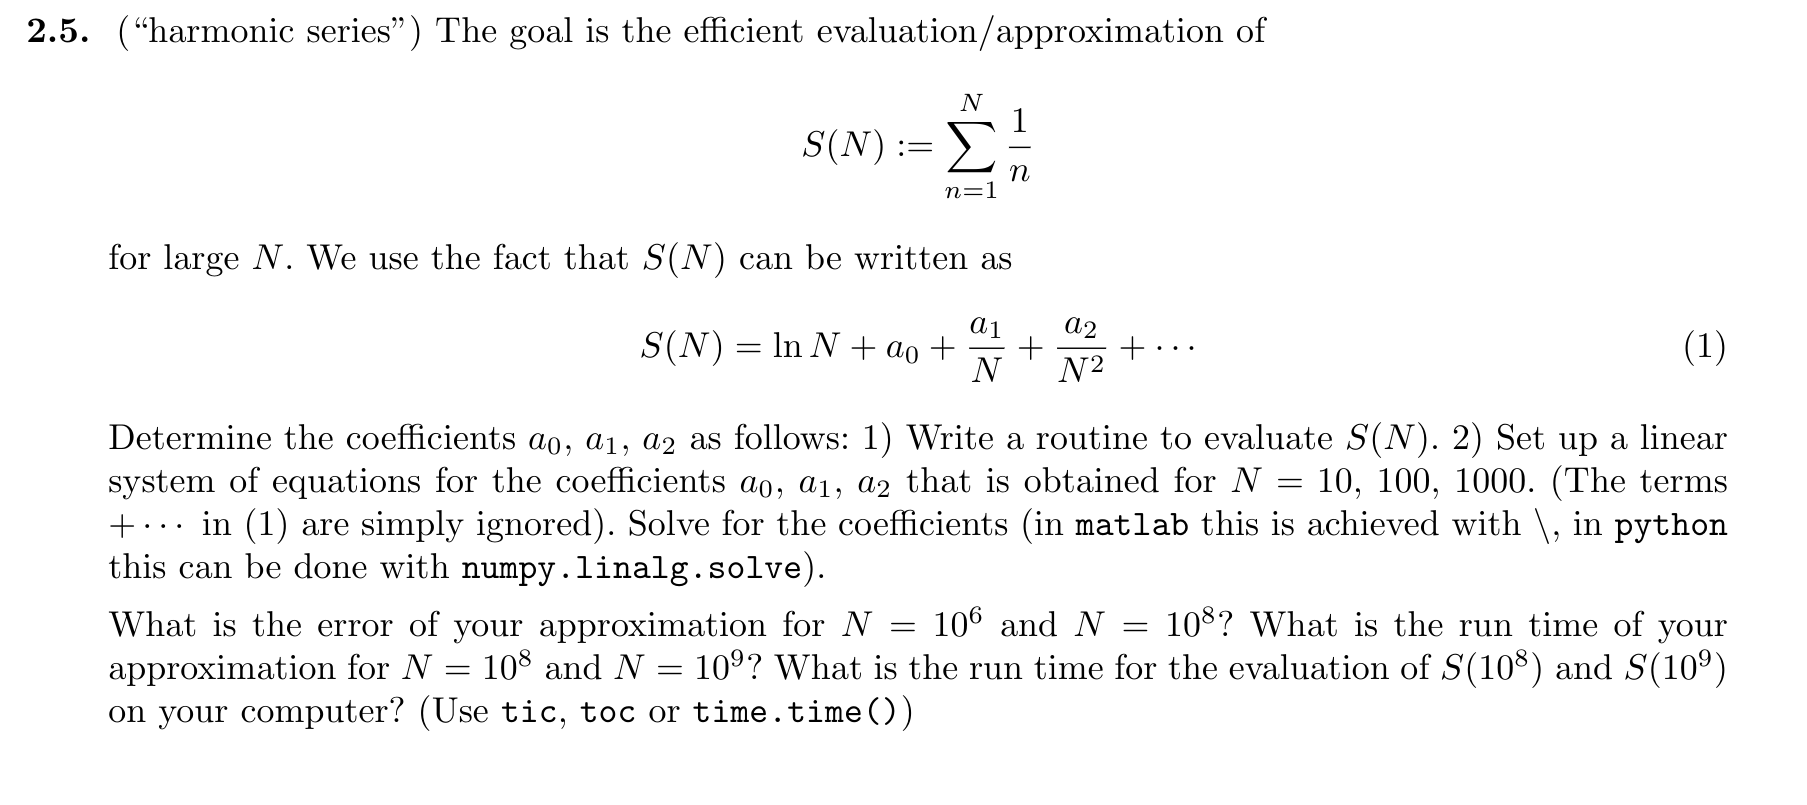

In [3]:
import time

S = lambda n: sum(1 / i for i in range(1, n + 1))

Ns_fit = (10, 100, 1000)
A = np.array([[1, 1/N, 1/N**2] for N in Ns_fit])
b = np.array([S(N) - np.log(N) for N in Ns_fit])
a0, a1, a2 = np.linalg.solve(A, b)
print(f"a0 = {a0}, a1 = {a1}, a2 = {a2}")
print()

def S_approx(N):
    return np.log(N) + a0 + a1/N + a2/N**2

print(f"{'N':>6} | {'error':>10} | {'t direct [s]':>12} | {'t approx [s]':>12}")
for N in (10**6, 10**8, 10**9):
    t0 = time.perf_counter(); s_dir = S(N);         t_dir = time.perf_counter() - t0
    t0 = time.perf_counter(); s_app = S_approx(N);  t_app = time.perf_counter() - t0
    print(f"1e{int(np.log10(N))}  | {abs(s_dir - s_app):10.2e} | {t_dir:12.4f} | {t_app:12.2e}")
    

a0 = 0.577215665822126, a1 = 0.49999898643133367, a2 = -0.08324034910515005

     N |      error | t direct [s] | t approx [s]
1e6  |   9.20e-10 |       0.0544 |     4.04e-05
1e8  |   9.21e-10 |       4.8912 |     4.63e-05
1e9  |   9.21e-10 |      48.9733 |     3.44e-05


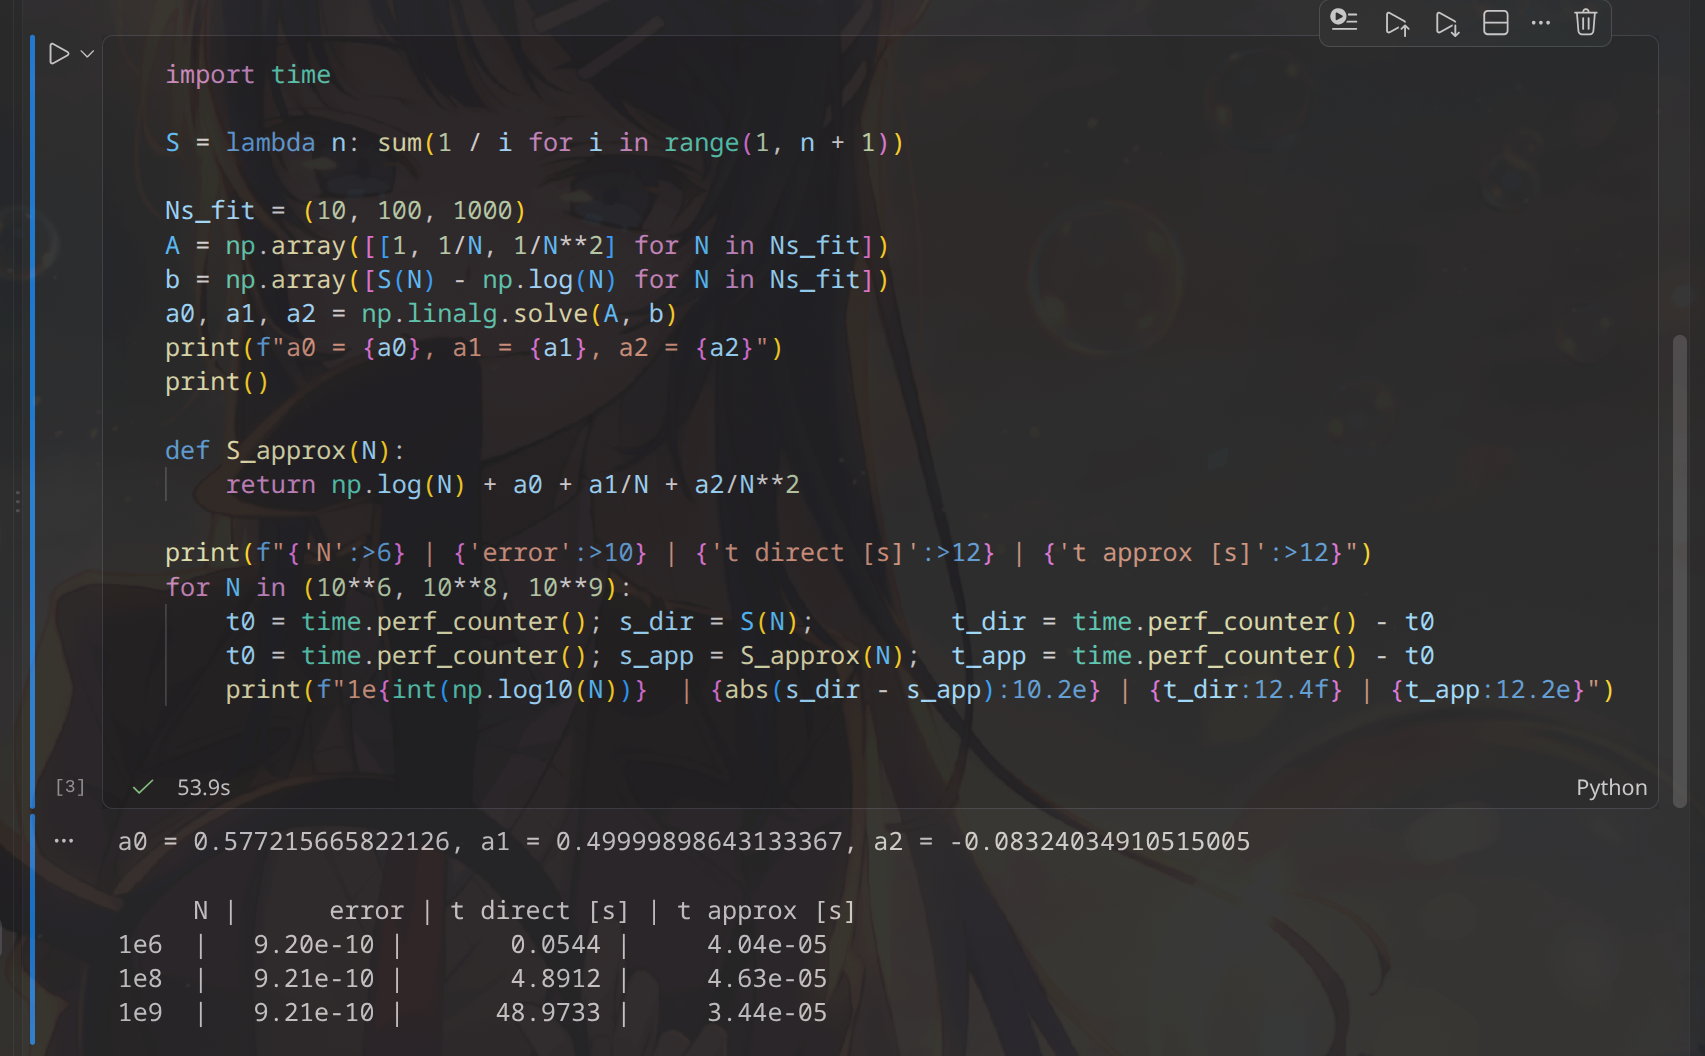